In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

In [2]:
import pandas as pd

df = pd.read_csv(
    r"C:\Users\anush\Installation\anaconda_projects\db\Supervised ML\minor project\loan_approval_data.csv")

df.head()

,Applicant_ID,Applicant_Income,Coapplicant_Income,Employment_Status,Age,Marital_Status,Dependents,Credit_Score,Existing_Loans,DTI_Ratio,Savings,Collateral_Value,Loan_Amount,Loan_Term,Loan_Purpose,Property_Area,Education_Level,Gender,Employer_Category,Loan_Approved
0,1.0,17795.0,1387.0,Salaried,51.0,Married,0.0,637.0,4.0,0.53,19403.0,45638.0,16619.0,84.0,Personal,Urban,Not Graduate,Female,Private,No
1,2.0,2860.0,2679.0,Salaried,46.0,Married,3.0,621.0,2.0,0.30,2580.0,49272.0,38687.0,NaN,Car,Semiurban,Graduate,NaN,Private,No
2,3.0,7390.0,2106.0,Salaried,25.0,Single,2.0,674.0,4.0,0.20,13844.0,6908.0,27943.0,72.0,NaN,Urban,NaN,Female,Government,Yes
3,4.0,13964.0,8173.0,Salaried,40.0,Married,2.0,579.0,3.0,0.31,9553.0,10844.0,27819.0,60.0,Business,Rural,Graduate,Female,Government,No
4,5.0,13284.0,4223.0,Self-employed,31.0,Single,2.0,721.0,1.0,0.29,9386.0,37629.0,12741.0,72.0,Car,NaN,Graduate,Male,Private,Yes


In [3]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 20 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Applicant_ID        950 non-null    float64
 1   Applicant_Income    950 non-null    float64
 2   Coapplicant_Income  950 non-null    float64
 3   Employment_Status   950 non-null    str    
 4   Age                 950 non-null    float64
 5   Marital_Status      950 non-null    str    
 6   Dependents          950 non-null    float64
 7   Credit_Score        950 non-null    float64
 8   Existing_Loans      950 non-null    float64
 9   DTI_Ratio           950 non-null    float64
 10  Savings             950 non-null    float64
 11  Collateral_Value    950 non-null    float64
 12  Loan_Amount         950 non-null    float64
 13  Loan_Term           950 non-null    float64
 14  Loan_Purpose        950 non-null    str    
 15  Property_Area       950 non-null    str    
 16  Education_Level   

In [4]:
df.isnull().sum()



Applicant_ID          50
Applicant_Income      50
Coapplicant_Income    50
Employment_Status     50
Age                   50
Marital_Status        50
Dependents            50
Credit_Score          50
Existing_Loans        50
DTI_Ratio             50
Savings               50
Collateral_Value      50
Loan_Amount           50
Loan_Term             50
Loan_Purpose          50
Property_Area         50
Education_Level       50
Gender                50
Employer_Category     50
Loan_Approved         50
dtype: int64

In [5]:
df.describe()


,Applicant_ID,Applicant_Income,Coapplicant_Income,Age,Dependents,Credit_Score,Existing_Loans,DTI_Ratio,Savings,Collateral_Value,Loan_Amount,Loan_Term
count,950.000000,950.000000,950.000000,950.000000,950.000000,950.000000,950.000000,950.000000,950.000000,950.000000,950.000000,950.000000
mean,501.220000,10852.571579,5082.455789,39.971579,1.474737,676.033684,1.950526,0.347263,9940.452632,24802.792632,20522.825263,48.000000
std,289.608451,5061.632859,2943.161570,11.139797,1.105067,71.346015,1.406246,0.144341,5860.736885,14345.696031,11504.142575,24.245322
min,1.000000,2009.000000,1.000000,21.000000,0.000000,550.000000,0.000000,0.100000,65.000000,36.000000,1015.000000,12.000000
25%,250.250000,6730.750000,2472.750000,30.250000,1.000000,616.250000,1.000000,0.220000,4760.250000,12698.250000,9806.250000,24.000000
50%,499.500000,10548.000000,5205.500000,40.000000,1.000000,678.000000,2.000000,0.340000,9880.500000,24321.000000,21210.500000,48.000000
75%,752.750000,15190.000000,7620.750000,49.000000,2.000000,737.000000,3.000000,0.480000,15074.500000,36947.000000,30263.000000,72.000000
max,1000.000000,19988.000000,9996.000000,59.000000,3.000000,799.000000,4.000000,0.600000,19996.000000,49954.000000,39995.000000,84.000000


In [6]:
#handle Missing Data

from sklearn.impute import SimpleImputer

# Select categorical and numerical columns
categorical_cols = df.select_dtypes(include=["str"]).columns
numerical_cols = df.select_dtypes(include=["number"]).columns

# Fill numerical null values with mean
num_imp = SimpleImputer(strategy="mean")
df[numerical_cols] = num_imp.fit_transform(df[numerical_cols])

# Fill categorical null values with most frequent value
cat_imp = SimpleImputer(strategy="most_frequent")
df[categorical_cols] = cat_imp.fit_transform(df[categorical_cols])

# Display first 5 rows
display(df.head())

# Check remaining null values
print(df.isnull().sum())



,Applicant_ID,Applicant_Income,Coapplicant_Income,Employment_Status,Age,Marital_Status,Dependents,Credit_Score,Existing_Loans,DTI_Ratio,Savings,Collateral_Value,Loan_Amount,Loan_Term,Loan_Purpose,Property_Area,Education_Level,Gender,Employer_Category,Loan_Approved
0,1.0,17795.0,1387.0,Salaried,51.0,Married,0.0,637.0,4.0,0.53,19403.0,45638.0,16619.0,84.0,Personal,Urban,Not Graduate,Female,Private,No
1,2.0,2860.0,2679.0,Salaried,46.0,Married,3.0,621.0,2.0,0.30,2580.0,49272.0,38687.0,48.0,Car,Semiurban,Graduate,Male,Private,No
2,3.0,7390.0,2106.0,Salaried,25.0,Single,2.0,674.0,4.0,0.20,13844.0,6908.0,27943.0,72.0,Business,Urban,Graduate,Female,Government,Yes
3,4.0,13964.0,8173.0,Salaried,40.0,Married,2.0,579.0,3.0,0.31,9553.0,10844.0,27819.0,60.0,Business,Rural,Graduate,Female,Government,No
4,5.0,13284.0,4223.0,Self-employed,31.0,Single,2.0,721.0,1.0,0.29,9386.0,37629.0,12741.0,72.0,Car,Urban,Graduate,Male,Private,Yes


Applicant_ID          0
Applicant_Income      0
Coapplicant_Income    0
Employment_Status     0
Age                   0
Marital_Status        0
Dependents            0
Credit_Score          0
Existing_Loans        0
DTI_Ratio             0
Savings               0
Collateral_Value      0
Loan_Amount           0
Loan_Term             0
Loan_Purpose          0
Property_Area         0
Education_Level       0
Gender                0
Employer_Category     0
Loan_Approved         0
dtype: int64


In [7]:
#EDA-exploratory data analysis
classes_count = df["Loan_Approved"].value_counts()
classes_count

Loan_Approved
No     702
Yes    298
Name: count, dtype: int64

Text(0.5, 1.0, 'Is loan Approved or not?')

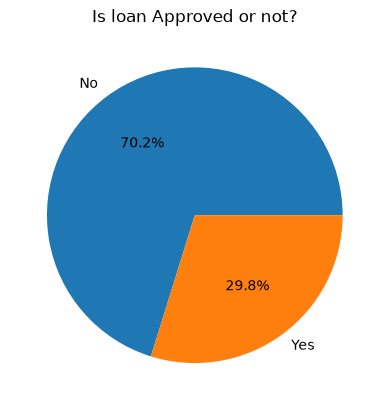

In [8]:
plt.pie(classes_count,labels=["No","Yes"],autopct="%1.1f%%")
plt.title("Is loan Approved or not?")

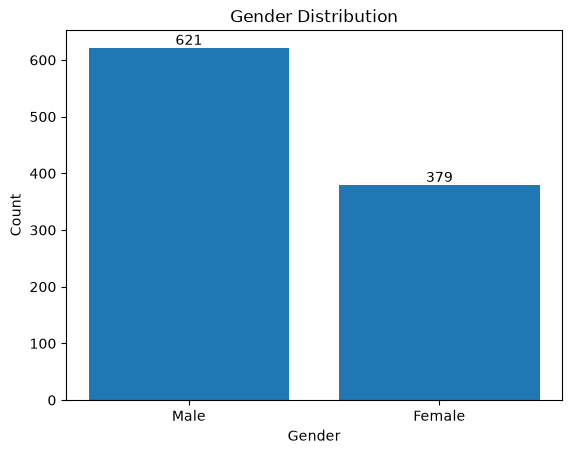

In [9]:
#analyze Categories
gender_cnt = df["Gender"].value_counts()

bars = plt.bar(gender_cnt.index, gender_cnt.values)
plt.bar_label(bars)

plt.title("Gender Distribution")
plt.xlabel("Gender")
plt.ylabel("Count")

plt.show()

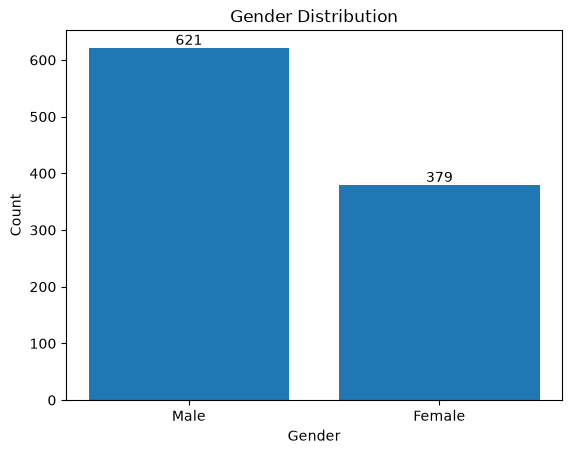

In [10]:
gender_cnt = df["Gender"].value_counts()

bars = plt.bar(gender_cnt.index, gender_cnt.values)
plt.bar_label(bars)

plt.title("Gender Distribution")
plt.xlabel("Gender")
plt.ylabel("Count")

plt.show()

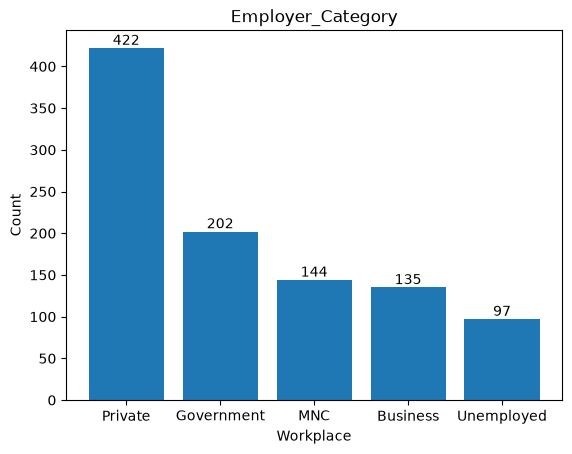

In [11]:
category_cnt = df["Employer_Category"].value_counts()

bars = plt.bar(category_cnt.index, category_cnt.values)
plt.bar_label(bars)

plt.title("Employer_Category")
plt.xlabel("Workplace")
plt.ylabel("Count")

plt.show()


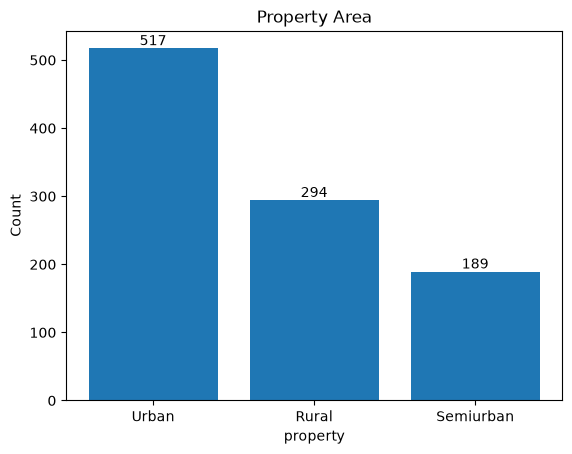

In [12]:
property_cnt = df["Property_Area"].value_counts()

bars = plt.bar(property_cnt.index, property_cnt.values)
plt.bar_label(bars)

plt.title("Property Area")
plt.xlabel("property")
plt.ylabel("Count")

plt.show()

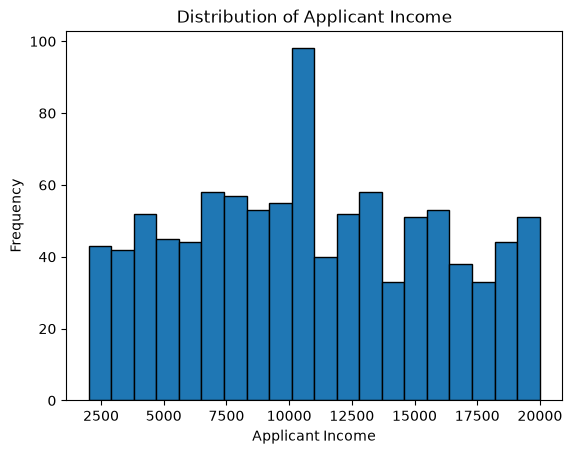

In [13]:
#analyze Income
plt.hist(df["Applicant_Income"], bins=20,edgecolor="black")

plt.title("Distribution of Applicant Income")
plt.xlabel("Applicant Income")
plt.ylabel("Frequency")

plt.show()

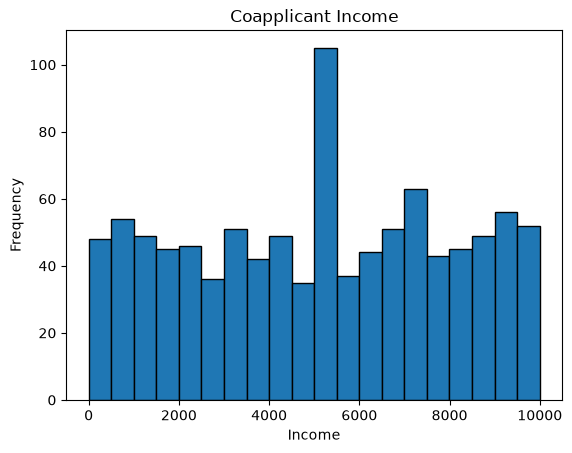

In [14]:
plt.hist(df["Coapplicant_Income"], bins=20,edgecolor="black")

plt.title("Coapplicant Income")
plt.ylabel("Frequency")
plt.xlabel("Income")
plt.show()

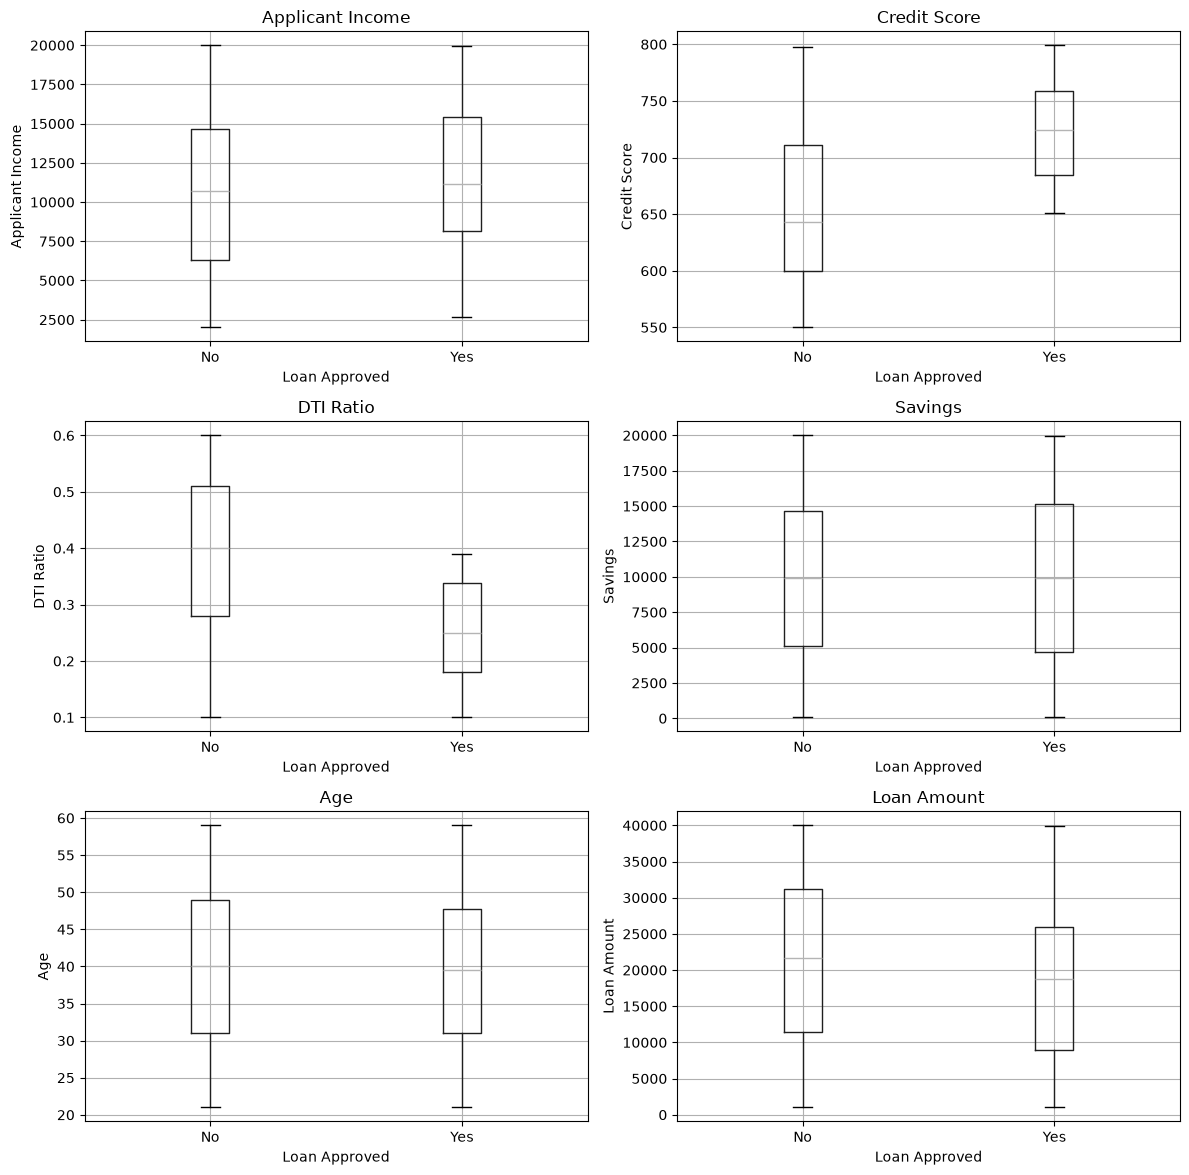

In [15]:

import matplotlib.pyplot as plt

# Create 6 box plots in a 3x2 layout
fig, axes = plt.subplots(3, 2, figsize=(12, 12))

# Applicant Income
df.boxplot(column="Applicant_Income",
           by="Loan_Approved", ax=axes[0, 0])

# Credit Score
df.boxplot(column="Credit_Score",
           by="Loan_Approved", ax=axes[0, 1])

# DTI Ratio
df.boxplot(column="DTI_Ratio",
           by="Loan_Approved", ax=axes[1, 0])

# Savings
df.boxplot(column="Savings",
           by="Loan_Approved", ax=axes[1, 1])

# Age
df.boxplot(column="Age",
           by="Loan_Approved", ax=axes[2, 0])

# Loan Amount
df.boxplot(column="Loan_Amount",
           by="Loan_Approved", ax=axes[2, 1])

# Add titles and labels
titles = [
    "Applicant Income", "Credit Score",
    "DTI Ratio", "Savings",
    "Age", "Loan Amount"
]

for ax, title in zip(axes.flat, titles):
    ax.set_title(title)
    ax.set_xlabel("Loan Approved")
    ax.set_ylabel(title)

# Remove automatic overall title
plt.suptitle("")

plt.tight_layout()
plt.show()


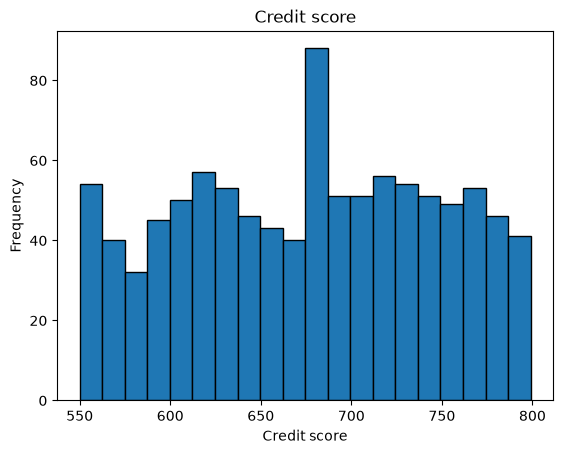

In [16]:
plt.hist(df["Credit_Score"], bins=20,edgecolor="black")

plt.title("Credit score")
plt.ylabel("Frequency")
plt.xlabel("Credit score")
plt.show()

In [17]:
df =df.drop("Applicant_ID",axis=1)
df.head()

,Applicant_Income,Coapplicant_Income,Employment_Status,Age,Marital_Status,Dependents,Credit_Score,Existing_Loans,DTI_Ratio,Savings,Collateral_Value,Loan_Amount,Loan_Term,Loan_Purpose,Property_Area,Education_Level,Gender,Employer_Category,Loan_Approved
0,17795.0,1387.0,Salaried,51.0,Married,0.0,637.0,4.0,0.53,19403.0,45638.0,16619.0,84.0,Personal,Urban,Not Graduate,Female,Private,No
1,2860.0,2679.0,Salaried,46.0,Married,3.0,621.0,2.0,0.30,2580.0,49272.0,38687.0,48.0,Car,Semiurban,Graduate,Male,Private,No
2,7390.0,2106.0,Salaried,25.0,Single,2.0,674.0,4.0,0.20,13844.0,6908.0,27943.0,72.0,Business,Urban,Graduate,Female,Government,Yes
3,13964.0,8173.0,Salaried,40.0,Married,2.0,579.0,3.0,0.31,9553.0,10844.0,27819.0,60.0,Business,Rural,Graduate,Female,Government,No
4,13284.0,4223.0,Self-employed,31.0,Single,2.0,721.0,1.0,0.29,9386.0,37629.0,12741.0,72.0,Car,Urban,Graduate,Male,Private,Yes


In [18]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 19 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Applicant_Income    1000 non-null   float64
 1   Coapplicant_Income  1000 non-null   float64
 2   Employment_Status   1000 non-null   str    
 3   Age                 1000 non-null   float64
 4   Marital_Status      1000 non-null   str    
 5   Dependents          1000 non-null   float64
 6   Credit_Score        1000 non-null   float64
 7   Existing_Loans      1000 non-null   float64
 8   DTI_Ratio           1000 non-null   float64
 9   Savings             1000 non-null   float64
 10  Collateral_Value    1000 non-null   float64
 11  Loan_Amount         1000 non-null   float64
 12  Loan_Term           1000 non-null   float64
 13  Loan_Purpose        1000 non-null   str    
 14  Property_Area       1000 non-null   str    
 15  Education_Level     1000 non-null   str    
 16  Gender            

In [19]:
from sklearn.preprocessing import LabelEncoder, OneHotEncoder
le=LabelEncoder()
df["Education_Level"]=le.fit_transform(df["Education_Level"])
df["Loan_Approved"]=le.fit_transform(df["Loan_Approved"])


In [20]:
df.head()

,Applicant_Income,Coapplicant_Income,Employment_Status,Age,Marital_Status,Dependents,Credit_Score,Existing_Loans,DTI_Ratio,Savings,Collateral_Value,Loan_Amount,Loan_Term,Loan_Purpose,Property_Area,Education_Level,Gender,Employer_Category,Loan_Approved
0,17795.0,1387.0,Salaried,51.0,Married,0.0,637.0,4.0,0.53,19403.0,45638.0,16619.0,84.0,Personal,Urban,1,Female,Private,0
1,2860.0,2679.0,Salaried,46.0,Married,3.0,621.0,2.0,0.30,2580.0,49272.0,38687.0,48.0,Car,Semiurban,0,Male,Private,0
2,7390.0,2106.0,Salaried,25.0,Single,2.0,674.0,4.0,0.20,13844.0,6908.0,27943.0,72.0,Business,Urban,0,Female,Government,1
3,13964.0,8173.0,Salaried,40.0,Married,2.0,579.0,3.0,0.31,9553.0,10844.0,27819.0,60.0,Business,Rural,0,Female,Government,0
4,13284.0,4223.0,Self-employed,31.0,Single,2.0,721.0,1.0,0.29,9386.0,37629.0,12741.0,72.0,Car,Urban,0,Male,Private,1


In [21]:
from sklearn.preprocessing import OneHotEncoder
import pandas as pd

cols = [
    "Employment_Status",
    "Marital_Status",
    "Loan_Purpose",
    "Property_Area",
    "Gender",
    "Employer_Category"
]

ohe = OneHotEncoder(
    drop="first",
    sparse_output=False,
    handle_unknown="ignore"
)

encoded = ohe.fit_transform(df[cols])

encoded_df = pd.DataFrame(
    encoded,
    columns=ohe.get_feature_names_out(),
    index=df.index
)

df = pd.concat(
    [df.drop(columns=cols), encoded_df],
    axis=1
)
print(df.select_dtypes(include=["object", "str"]).columns.tolist())
display(df.head())

[]


,Applicant_Income,Coapplicant_Income,Age,Dependents,Credit_Score,Existing_Loans,DTI_Ratio,Savings,Collateral_Value,Loan_Amount,...,Loan_Purpose_Education,Loan_Purpose_Home,Loan_Purpose_Personal,Property_Area_Semiurban,Property_Area_Urban,Gender_Male,Employer_Category_Government,Employer_Category_MNC,Employer_Category_Private,Employer_Category_Unemployed
0,17795.0,1387.0,51.0,0.0,637.0,4.0,0.53,19403.0,45638.0,16619.0,...,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
1,2860.0,2679.0,46.0,3.0,621.0,2.0,0.30,2580.0,49272.0,38687.0,...,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0
2,7390.0,2106.0,25.0,2.0,674.0,4.0,0.20,13844.0,6908.0,27943.0,...,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0
3,13964.0,8173.0,40.0,2.0,579.0,3.0,0.31,9553.0,10844.0,27819.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
4,13284.0,4223.0,31.0,2.0,721.0,1.0,0.29,9386.0,37629.0,12741.0,...,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0


<Axes: >

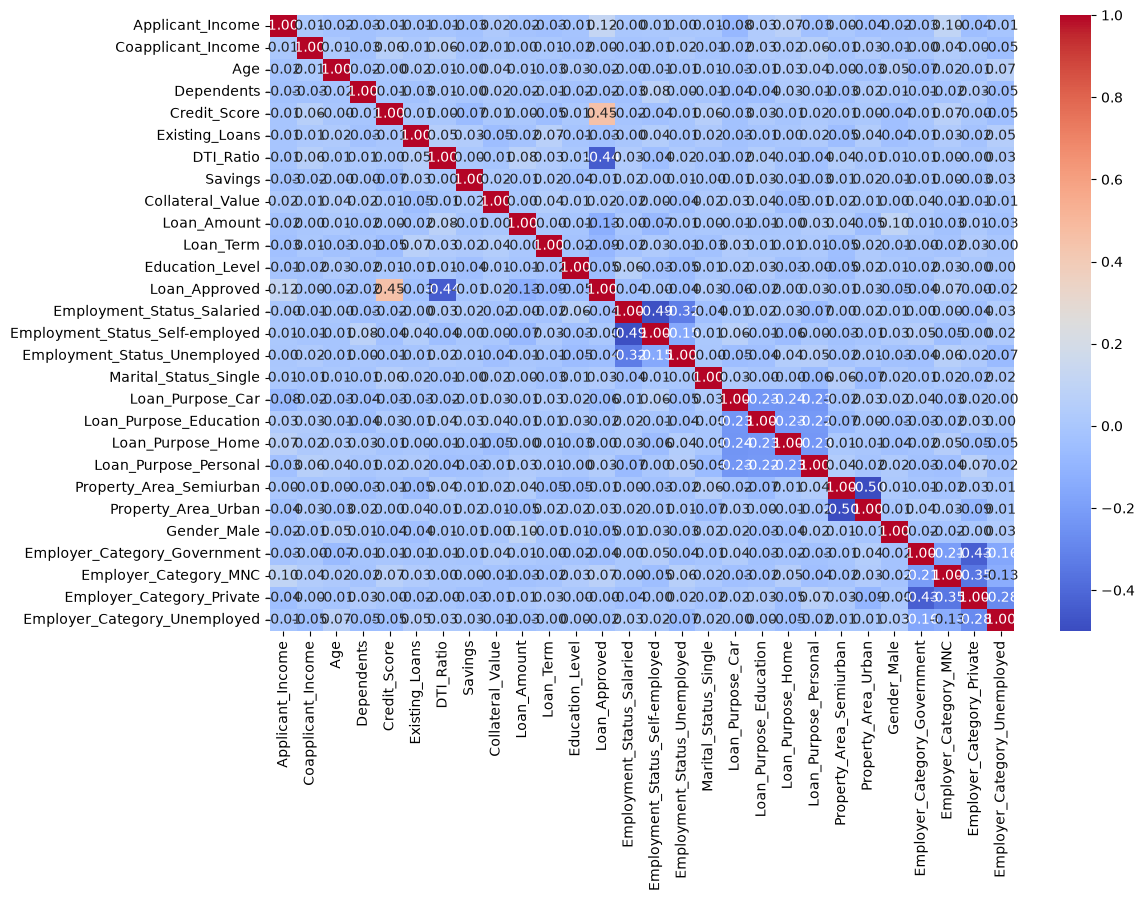

In [22]:
num_cols = df.select_dtypes(include="number")
corr_matrix = num_cols.corr()
import seaborn as sns
plt.figure(figsize=(12, 8))

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm"
)

In [23]:
X = df.drop("Loan_Approved", axis=1)
y = df["Loan_Approved"]
X.head()

,Applicant_Income,Coapplicant_Income,Age,Dependents,Credit_Score,Existing_Loans,DTI_Ratio,Savings,Collateral_Value,Loan_Amount,...,Loan_Purpose_Education,Loan_Purpose_Home,Loan_Purpose_Personal,Property_Area_Semiurban,Property_Area_Urban,Gender_Male,Employer_Category_Government,Employer_Category_MNC,Employer_Category_Private,Employer_Category_Unemployed
0,17795.0,1387.0,51.0,0.0,637.0,4.0,0.53,19403.0,45638.0,16619.0,...,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
1,2860.0,2679.0,46.0,3.0,621.0,2.0,0.30,2580.0,49272.0,38687.0,...,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0
2,7390.0,2106.0,25.0,2.0,674.0,4.0,0.20,13844.0,6908.0,27943.0,...,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0
3,13964.0,8173.0,40.0,2.0,579.0,3.0,0.31,9553.0,10844.0,27819.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
4,13284.0,4223.0,31.0,2.0,721.0,1.0,0.29,9386.0,37629.0,12741.0,...,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0


In [24]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [25]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

# Fit on training data and scale it
X_train_scaled = scaler.fit_transform(X_train)

# Use the same scaler for testing data
X_test_scaled = scaler.transform(X_test)

In [26]:
from sklearn.linear_model import LogisticRegression

log_model = LogisticRegression()

log_model.fit(X_train_scaled, y_train)

y_pred = log_model.predict(X_test_scaled)

In [27]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

print("Logistic Regression Model")
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred, average="binary"))
print("Recall:", recall_score(y_test, y_pred, average="binary"))
print("F1-score:", f1_score(y_test, y_pred, average="binary"))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))

Logistic Regression Model
Accuracy: 0.865
Precision: 0.7833333333333333
Recall: 0.7704918032786885
F1-score: 0.7768595041322314
Confusion Matrix:
 [[126  13]
 [ 14  47]]


In [28]:
# KNN
from sklearn.neighbors import KNeighborsClassifier

knn_model = KNeighborsClassifier(n_neighbors=5)

knn_model.fit(X_train_scaled, y_train)

y_pred = knn_model.predict(X_test_scaled)

# Evaluation
print("KNN Model")
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1 Score:", f1_score(y_test, y_pred))
print("Accuracy:", accuracy_score(y_test, y_pred))
print("CM:", confusion_matrix(y_test, y_pred))

KNN Model
Precision: 0.6274509803921569
Recall: 0.5245901639344263
F1 Score: 0.5714285714285714
Accuracy: 0.76
CM: [[120  19]
 [ 29  32]]


In [29]:
# Naive Bayes

from sklearn.naive_bayes import GaussianNB

nb_model = GaussianNB()
nb_model.fit(X_train_scaled, y_train)

y_pred = nb_model.predict(X_test_scaled)

# Evaluation
print("Naive Bayes Model")
print("Precision: ", precision_score(y_test, y_pred))
print("Recall: ", recall_score(y_test, y_pred))
print("F1 score: ", f1_score(y_test, y_pred))
print("Accuracy: ", accuracy_score(y_test, y_pred))
print("CM: ", confusion_matrix(y_test, y_pred))

Naive Bayes Model
Precision:  0.8035714285714286
Recall:  0.7377049180327869
F1 score:  0.7692307692307693
Accuracy:  0.865
CM:  [[128  11]
 [ 16  45]]


In [30]:
# Add or Transform features
df["DTI_Ratio_sq"] = df["DTI_Ratio"] ** 2
df["Credit_Score_sq"] = df["Credit_Score"] ** 2

X = df.drop(columns=["Loan_Approved", "Credit_Score", "DTI_Ratio"])
y = df["Loan_Approved"]

X.head()

,Applicant_Income,Coapplicant_Income,Age,Dependents,Existing_Loans,Savings,Collateral_Value,Loan_Amount,Loan_Term,Education_Level,...,Loan_Purpose_Personal,Property_Area_Semiurban,Property_Area_Urban,Gender_Male,Employer_Category_Government,Employer_Category_MNC,Employer_Category_Private,Employer_Category_Unemployed,DTI_Ratio_sq,Credit_Score_sq
0,17795.0,1387.0,51.0,0.0,4.0,19403.0,45638.0,16619.0,84.0,1,...,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.2809,405769.0
1,2860.0,2679.0,46.0,3.0,2.0,2580.0,49272.0,38687.0,48.0,0,...,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0900,385641.0
2,7390.0,2106.0,25.0,2.0,4.0,13844.0,6908.0,27943.0,72.0,0,...,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0400,454276.0
3,13964.0,8173.0,40.0,2.0,3.0,9553.0,10844.0,27819.0,60.0,0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0961,335241.0
4,13284.0,4223.0,31.0,2.0,1.0,9386.0,37629.0,12741.0,72.0,0,...,0.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,0.0841,519841.0


In [31]:
# Train test split
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Scaling
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

# Fit on training data and scale it
X_train_scaled = scaler.fit_transform(X_train)

# Use the same scaler for testing data
X_test_scaled = scaler.transform(X_test)

X_train.head()

,Applicant_Income,Coapplicant_Income,Age,Dependents,Existing_Loans,Savings,Collateral_Value,Loan_Amount,Loan_Term,Education_Level,...,Loan_Purpose_Personal,Property_Area_Semiurban,Property_Area_Urban,Gender_Male,Employer_Category_Government,Employer_Category_MNC,Employer_Category_Private,Employer_Category_Unemployed,DTI_Ratio_sq,Credit_Score_sq
29,5890.000000,8041.0,31.000000,0.0,0.000000,11906.0,8150.000000,29287.000000,12.0,1,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0121,363609.000000
535,4779.000000,529.0,50.000000,0.0,0.000000,5369.0,5430.000000,14786.000000,72.0,1,...,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0441,376996.000000
695,10852.571579,8927.0,36.000000,0.0,4.000000,3186.0,24802.792632,20522.825263,48.0,1,...,1.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0484,341056.000000
557,2384.000000,2113.0,39.971579,1.0,4.000000,11882.0,48542.000000,13312.000000,24.0,0,...,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.1156,527076.000000
836,5228.000000,5249.0,42.000000,1.0,1.950526,17669.0,24802.792632,13906.000000,84.0,0,...,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0324,457021.542187


In [32]:
from sklearn.linear_model import LogisticRegression

log_model = LogisticRegression()

log_model.fit(X_train_scaled, y_train)

y_pred = log_model.predict(X_test_scaled)


In [33]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

print("Logistic Regression Model")
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred, average="binary"))
print("Recall:", recall_score(y_test, y_pred, average="binary"))
print("F1-score:", f1_score(y_test, y_pred, average="binary"))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))

Logistic Regression Model
Accuracy: 0.875
Precision: 0.7903225806451613
Recall: 0.8032786885245902
F1-score: 0.7967479674796748
Confusion Matrix:
 [[126  13]
 [ 12  49]]


In [34]:
# KNN
from sklearn.neighbors import KNeighborsClassifier

knn_model = KNeighborsClassifier(n_neighbors=5)

knn_model.fit(X_train_scaled, y_train)

y_pred_knn = knn_model.predict(X_test_scaled)
print("KNN Model")
print("Accuracy:", accuracy_score(y_test, y_pred_knn))

print("Precision:", precision_score(
    y_test, y_pred_knn, average="weighted", zero_division=0
))

print("Recall:", recall_score(
    y_test, y_pred_knn, average="weighted", zero_division=0
))

print("F1-score:", f1_score(
    y_test, y_pred_knn, average="weighted", zero_division=0
))

print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred_knn))

KNN Model
Accuracy: 0.755
Precision: 0.7451000000000001
Recall: 0.755
F1-score: 0.7475229901181457
Confusion Matrix:
 [[120  19]
 [ 30  31]]


In [35]:
# Naive Bayes
from sklearn.naive_bayes import GaussianNB

nb_model = GaussianNB()

nb_model.fit(X_train_scaled, y_train)

y_pred_nb = nb_model.predict(X_test_scaled)
print("Naive Bayes Model")
print("Precision:", precision_score(y_test, y_pred_nb))
print("Recall:", recall_score(y_test, y_pred_nb))
print("F1 score:", f1_score(y_test, y_pred_nb))
print("Accuracy:", accuracy_score(y_test, y_pred_nb))
print("CM:\n", confusion_matrix(y_test, y_pred_nb))


Naive Bayes Model
Precision: 0.7833333333333333
Recall: 0.7704918032786885
F1 score: 0.7768595041322314
Accuracy: 0.865
CM:
 [[126  13]
 [ 14  47]]


In [36]:

import joblib

joblib.dump(log_model, "loan_model.pkl")
joblib.dump(scaler, "scaler.pkl")
joblib.dump(list(X.columns), "feature_columns.pkl")

print("All three files saved successfully!")


All three files saved successfully!


In [37]:
import joblib

joblib.dump(ohe, "onehot_encoder.pkl")

print("One-hot encoder saved successfully!")

One-hot encoder saved successfully!


In [38]:
import os
print(os.getcwd())

C:\Users\anush\Installation\anaconda_projects\db\Supervised ML\minor project


In [39]:
import joblib

joblib.dump(log_model, "loan_model_logistic.pkl")
joblib.dump(knn_model, "loan_model_knn.pkl")
joblib.dump(nb_model, "loan_model_nb.pkl")

joblib.dump(scaler, "scaler.pkl")
joblib.dump(ohe, "onehot_encoder.pkl")
joblib.dump(list(X.columns), "feature_columns.pkl")

print("Models saved successfully!")

Models saved successfully!


In [40]:
print("Missing values in df:", df.isnull().sum().sum())
print("Missing values in X_train:", X_train.isnull().sum().sum())
print("Missing values in X_test:", X_test.isnull().sum().sum())

Missing values in df: 0
Missing values in X_train: 0
Missing values in X_test: 0


In [41]:
from sklearn.metrics import accuracy_score

models = {
    "Logistic Regression": log_model,
    "KNN": knn_model,
    "Gaussian Naive Bayes": nb_model
}

for name, model in models.items():
    y_pred = model.predict(X_test_scaled)
    accuracy = accuracy_score(y_test, y_pred)
    print(f"{name} Accuracy: {accuracy * 100:.2f}%")

Logistic Regression Accuracy: 87.50%
KNN Accuracy: 75.50%
Gaussian Naive Bayes Accuracy: 86.50%


In [42]:
from sklearn.metrics import (
    precision_score,
    recall_score,
    confusion_matrix
)

models = {
    "Logistic Regression": log_model,
    "KNN": knn_model,
    "Gaussian Naive Bayes": nb_model
}

for name, model in models.items():
    y_pred = model.predict(X_test_scaled)

    print("\n", name)
    print("Precision:", precision_score(y_test, y_pred, average="weighted"))
    print("Recall:", recall_score(y_test, y_pred, average="weighted"))
    print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))


 Logistic Regression
Precision: 0.8756136044880785
Recall: 0.875
Confusion Matrix:
 [[126  13]
 [ 12  49]]

 KNN
Precision: 0.7451000000000001
Recall: 0.755
Confusion Matrix:
 [[120  19]
 [ 30  31]]

 Gaussian Naive Bayes
Precision: 0.8644166666666666
Recall: 0.865
Confusion Matrix:
 [[126  13]
 [ 14  47]]


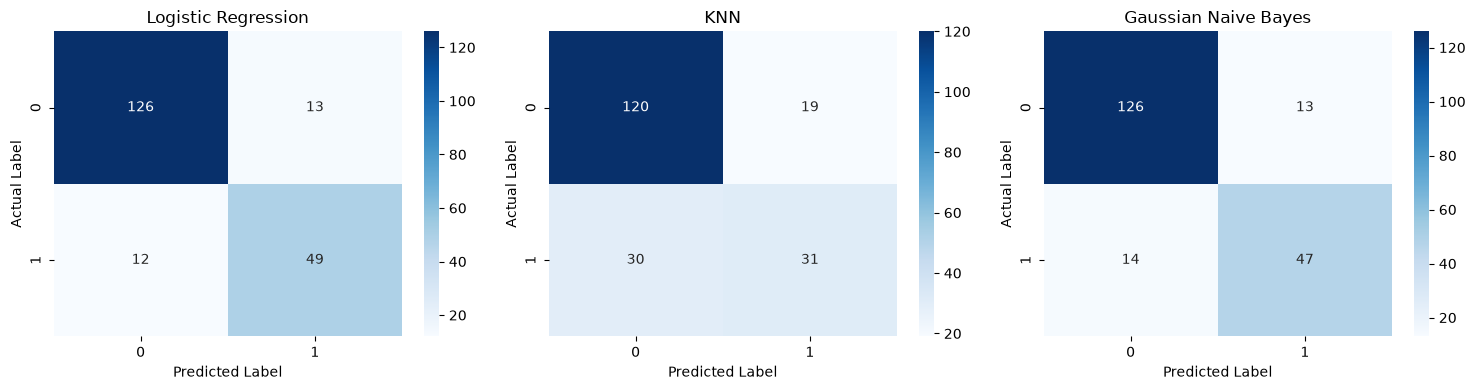

In [43]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

models = {
    "Logistic Regression": log_model,
    "KNN": knn_model,
    "Gaussian Naive Bayes": nb_model
}

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, (name, model) in zip(axes, models.items()):
    y_pred = model.predict(X_test_scaled)
    cm = confusion_matrix(y_test, y_pred)

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        ax=ax
    )

    ax.set_title(name)
    ax.set_xlabel("Predicted Label")
    ax.set_ylabel("Actual Label")

plt.tight_layout()
plt.show()